# 1. Chargement des données

Dataset link: https://www.kaggle.com/code/anetakovacheva/predict-airline-passenger-satisfaction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
dataset = pd.read_csv("dataset.csv")

# 2. Analyse exploratoire (EDA)

In [2]:
dataset.head(10)

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Price
0,0,19149,Female,disloyal Customer,19.0,Business travel,Eco,353.0,3,4,...,5,5.0,5,2,2,2,0,3.0,dissatisfied,565
1,1,69112,Male,Loyal Customer,54.0,Business travel,Eco Plus,1088.0,5,2,...,2,3.0,5,1,2,5,0,0.0,satisfied,2573
2,2,4725,Female,disloyal Customer,23.0,Business travel,Business,977.0,2,0,...,5,4.0,4,5,5,5,0,0.0,dissatisfied,2339
3,3,115546,Male,Loyal Customer,58.0,Business travel,Business,2932.0,2,3,...,2,2.0,2,1,2,1,15,11.0,dissatisfied,2695
4,4,59440,Male,Loyal Customer,45.0,Business travel,Eco,667.0,1,0,...,4,2.0,2,4,2,2,0,5.0,dissatisfied,622
5,5,66133,Female,Loyal Customer,30.0,Personal Travel,Eco,641.0,1,4,...,4,1.0,4,4,3,5,0,0.0,neutral,1324
6,6,85665,Male,Loyal Customer,40.0,Business travel,Business,993.0,2,2,...,5,5.0,5,5,5,5,0,0.0,satisfied,3619
7,7,76698,Female,Loyal Customer,50.0,Personal Travel,Eco,602.0,2,0,...,5,3.0,5,4,5,3,0,0.0,neutral,1144
8,8,127935,Male,Loyal Customer,46.0,Personal Travel,Eco,2530.0,2,4,...,4,3.0,3,5,5,5,1,0.0,neutral,1668
9,9,102476,Female,Loyal Customer,54.0,Personal Travel,Eco,425.0,2,3,...,3,2.0,3,2,3,2,4,3.0,neutral,782


In [3]:
# (nombre de lignes, nombre de colonnes)
dataset.shape

(129880, 26)

In [4]:
# des informations sur le jeu de données
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 26 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         129880 non-null  int64  
 1   id                                 129880 non-null  int64  
 2   Gender                             129880 non-null  object 
 3   Customer Type                      129880 non-null  object 
 4   Age                                129754 non-null  float64
 5   Type of Travel                     129880 non-null  object 
 6   Class                              129880 non-null  object 
 7   Flight Distance                    129880 non-null  float64
 8   Inflight wifi service              129880 non-null  int64  
 9   Departure/Arrival time convenient  129880 non-null  int64  
 10  Ease of Online booking             129749 non-null  float64
 11  Gate location                      1297

In [5]:
# lister les valeurs catégorielles
dataset.select_dtypes(include="object").columns

Index(['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'], dtype='object')

In [6]:
# la taille des valeurs catégorielles
len(dataset.select_dtypes(include="object").columns)

5

In [7]:
# lister les valeurs numeriques
dataset.select_dtypes(include="number").columns

Index(['Unnamed: 0', 'id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'Price'],
      dtype='object')

In [8]:
# la taille des valeurs numériques
len(dataset.select_dtypes(include="number").columns)

21

In [9]:
# les statistiques
dataset.describe(include="all")

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Price
count,129880.000000,129880.000000,129880,129880,129754.000000,129880,129880,129880.000000,129880.000000,129880.000000,...,129880.000000,129747.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000,129880,129880.000000
unique,NaN,NaN,2,2,NaN,2,3,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN
top,NaN,NaN,Female,Loyal Customer,NaN,Business travel,Business,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,satisfied,NaN
freq,NaN,NaN,65899,106100,NaN,89693,62160,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56428,NaN
mean,64939.500000,64940.500000,NaN,NaN,35.470968,NaN,NaN,1309.378342,2.728696,3.057599,...,3.383023,3.350945,3.632114,3.306267,3.642193,3.286326,14.713713,15.091129,NaN,1883.004928
std,37493.270818,37493.270818,NaN,NaN,13.605360,NaN,NaN,1097.197896,1.329340,1.526741,...,1.287099,1.316236,1.180025,1.266185,1.176669,1.313682,38.071126,38.465650,NaN,1164.240921
min,0.000000,1.000000,NaN,NaN,6.000000,NaN,NaN,34.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,141.000000
25%,32469.750000,32470.750000,NaN,NaN,24.000000,NaN,NaN,455.000000,2.000000,2.000000,...,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000,NaN,895.000000
50%,64939.500000,64940.500000,NaN,NaN,36.000000,NaN,NaN,928.000000,3.000000,3.000000,...,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000,NaN,1472.000000
75%,97409.250000,97410.250000,NaN,NaN,46.000000,NaN,NaN,1918.000000,4.000000,4.000000,...,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000,NaN,2925.000000


In [10]:
# lister totues les colonnes
dataset.columns

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction', 'Price'],
      dtype='object')

# 3. Gestion des valeurs manquantes

In [11]:
# vérifier si il existe des valeurs manquantes dans le jeu de données
dataset.isnull().values.any()

True

In [12]:
# le nombre de valeurs manquantes dans le jeu de données
dataset.isnull().values.sum()

913

In [13]:
# lister les valeurs manquantes
dataset.isna().sum()

Unnamed: 0                             0
id                                     0
Gender                                 0
Customer Type                          0
Age                                  126
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking               131
Gate location                        130
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                     133
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction    

In [14]:
# imputation des valeurs manquantes
# exemple: imputation par la médiane pour les variables numériques
for col in ['Age', 'Ease of Online booking', 'Gate location', 'Leg room service', 'Arrival Delay in Minutes']:
    if dataset[col].dtype in ['int64', 'float64']:
        dataset[col].fillna(dataset[col].median(), inplace=True)

In [15]:
# vérifier encore les informations pour s'assurer que les valeurs manquantes sont traitées
print(dataset.isnull().sum())

Unnamed: 0                           0
id                                   0
Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
Price                    

# 4. Visualisations

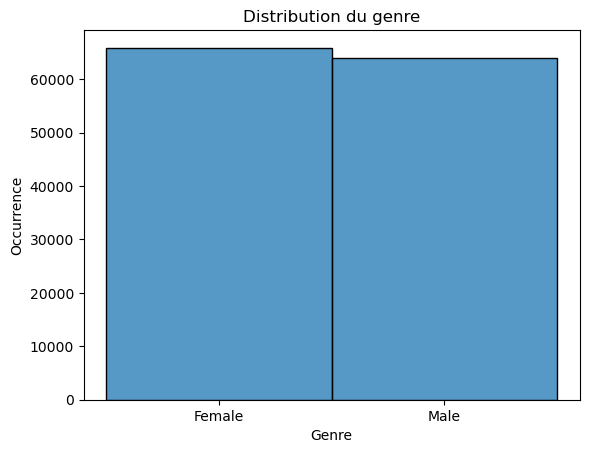

In [16]:
# La répartition du genre
sns.histplot(data=dataset, x="Gender", bins=range(2, 11))
plt.xlabel("Genre")
plt.ylabel("Occurrence")
plt.title("Distribution du genre")
plt.show()

In [17]:
dataset["Gender"].value_counts()

Gender
Female    65899
Male      63981
Name: count, dtype: int64

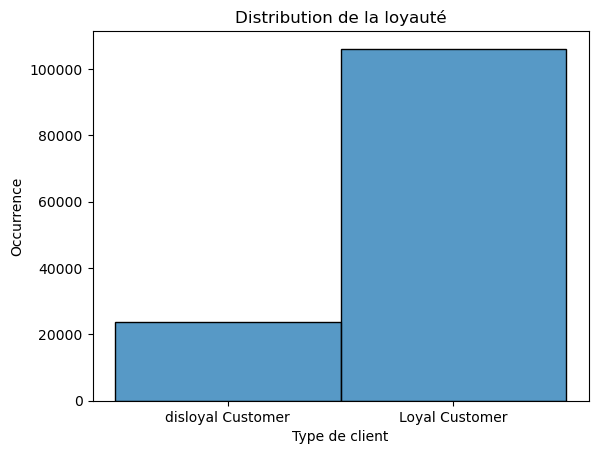

In [18]:
# La répartition de la loyauté
sns.histplot(data=dataset, x="Customer Type", bins=range(2, 11))
plt.xlabel("Type de client")
plt.ylabel("Occurrence")
plt.title("Distribution de la loyauté")
plt.show()

In [19]:
dataset["Customer Type"].value_counts()

Customer Type
Loyal Customer       106100
disloyal Customer     23780
Name: count, dtype: int64

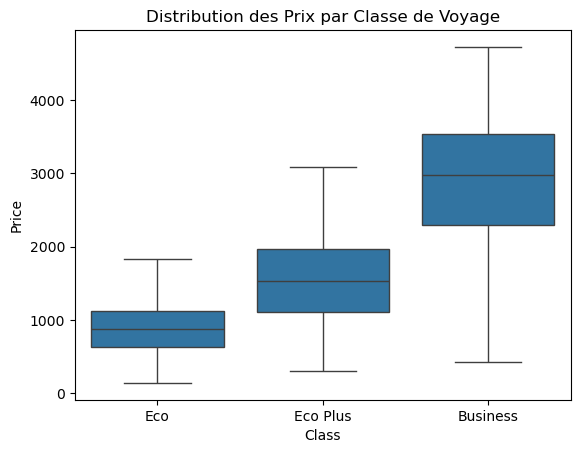

In [20]:
# Boxplots pour visualiser la distribution des prix en fonction des classes
sns.boxplot(x='Class', y='Price', data=dataset)
plt.xlabel("Class")
plt.ylabel("Price")
plt.title('Distribution des Prix par Classe de Voyage')
plt.show()

In [21]:
# groupement des données par classe et description des prix
class_price_description = dataset.groupby('Class')['Price'].describe()

# affichage de la description
print(class_price_description)

            count         mean         std    min     25%     50%     75%  \
Class                                                                       
Business  62160.0  2877.458542  854.575011  424.0  2296.0  2982.0  3544.0   
Eco       58309.0   877.895745  324.657039  141.0   632.0   879.0  1122.0   
Eco Plus   9411.0  1542.092658  567.681618  301.0  1111.0  1538.0  1968.0   

             max  
Class             
Business  4726.0  
Eco       1827.0  
Eco Plus  3087.0  


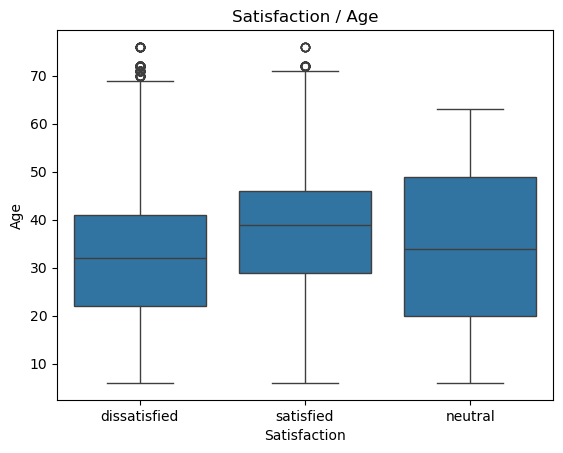

In [22]:
# La satisfaction par rapport à l'age
sns.boxplot(data=dataset, x="satisfaction", y="Age")
plt.xlabel("Satisfaction")
plt.ylabel("Age")
plt.title("Satisfaction / Age")
plt.show()

In [23]:
# groupement des données par satisfaction et age
satisfaction_age_description = dataset.groupby('satisfaction')['Age'].describe()

# affichage de la description
print(satisfaction_age_description)

                count       mean        std  min   25%   50%   75%   max
satisfaction                                                            
dissatisfied  37349.0  33.140486  12.770188  6.0  22.0  32.0  41.0  76.0
neutral       36103.0  34.621721  16.626302  6.0  20.0  34.0  49.0  63.0
satisfied     56428.0  37.558021  11.508074  6.0  29.0  39.0  46.0  76.0


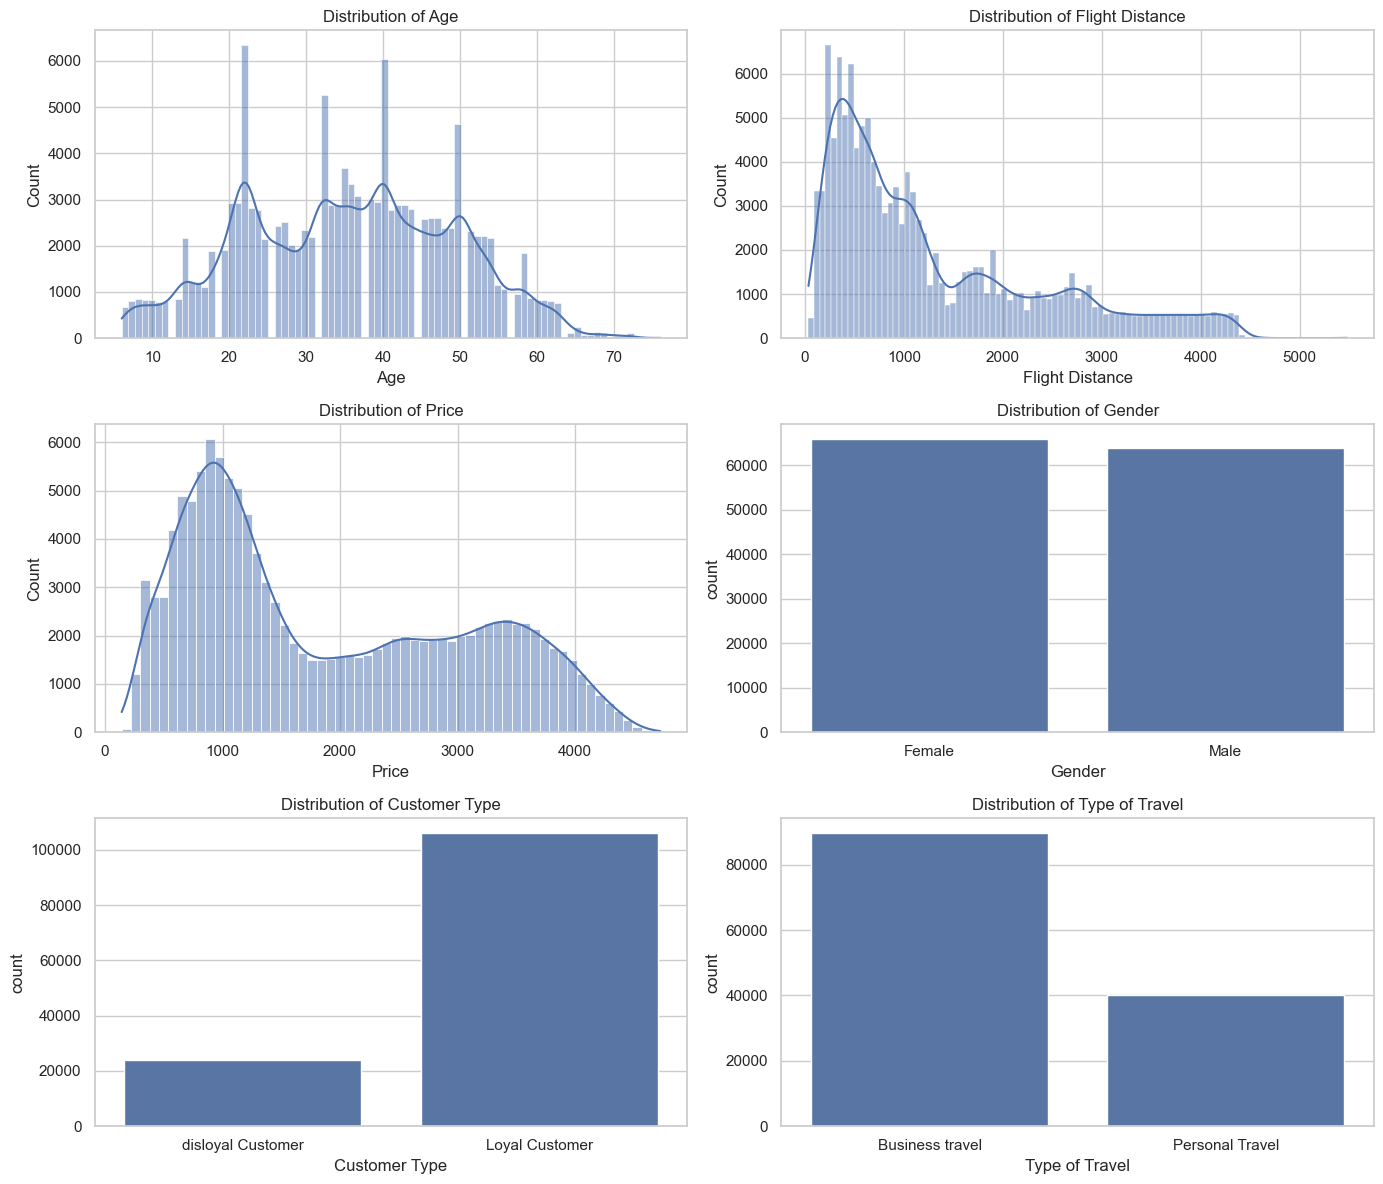

In [24]:
# Set the aesthetic style of the plots
sns.set(style="whitegrid")

# Create a figure to hold the plots
fig, ax = plt.subplots(3, 2, figsize=(14, 12))

# Histograms for continuous variables
sns.histplot(dataset['Age'], kde=True, ax=ax[0, 0])
ax[0, 0].set_title('Distribution of Age')

sns.histplot(dataset['Flight Distance'], kde=True, ax=ax[0, 1])
ax[0, 1].set_title('Distribution of Flight Distance')

sns.histplot(dataset['Price'], kde=True, ax=ax[1, 0])
ax[1, 0].set_title('Distribution of Price')

# Bar plots for categorical variables
sns.countplot(x='Gender', data=dataset, ax=ax[1, 1])
ax[1, 1].set_title('Distribution of Gender')

sns.countplot(x='Customer Type', data=dataset, ax=ax[2, 0])
ax[2, 0].set_title('Distribution of Customer Type')

sns.countplot(x='Type of Travel', data=dataset, ax=ax[2, 1])
ax[2, 1].set_title('Distribution of Type of Travel')

# Adjust layout
plt.tight_layout()
plt.show()

# 5. Tests

## T-test

In [25]:
# Comparer les âges des clients satisfaits et insatisfaits
from scipy.stats import ttest_ind

satisfied_age = dataset[dataset['satisfaction'] == 'satisfied']['Age']
dissatisfied_age = dataset[dataset['satisfaction'] == 'dissatisfied']['Age']

t_stat, p_value = ttest_ind(satisfied_age, dissatisfied_age)
print(f"T-statistic: {t_stat}, P-value: {p_value}")

T-statistic: 55.064924944022756, P-value: 0.0


## Test du Chi-deux

In [26]:
# vérifier l'association entre le type de client et la satisfaction
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(dataset['Customer Type'], dataset['satisfaction'])
chi2, p, dof, ex = chi2_contingency(contingency_table)
print(f"Chi2: {chi2}, P-value: {p}")

Chi2: 32248.59327330478, P-value: 0.0


## ANOVA (Analyse de la variance)

In [27]:
# Comparer les prix entre les différentes classes
from scipy.stats import f_oneway

eco_prices = dataset[dataset['Class'] == 'Eco']['Price']
eco_plus_prices = dataset[dataset['Class'] == 'Eco Plus']['Price']
business_prices = dataset[dataset['Class'] == 'Business']['Price']

f_stat, p_value = f_oneway(eco_prices, eco_plus_prices, business_prices)
print(f"F-statistic: {f_stat}, P-value: {p_value}")

F-statistic: 144545.0196514146, P-value: 0.0


## Coefficient de corrélation de Pearson

In [28]:
from scipy.stats import pearsonr

age = dataset['Age']
price = dataset['Price']

correlation, p_value = pearsonr(age, price)
print(f"Pearson Correlation: {correlation}, P-value: {p_value}")

Pearson Correlation: 0.1744102103526226, P-value: 0.0


### Résumé des conclusions:
* Test t de Student : Les âges des clients satisfaits et insatisfaits sont significativement différents.
* Test du Chi-deux : Il existe une association significative entre le type de client (loyal ou non) et la satisfaction.
* ANOVA : Les prix des billets diffèrent significativement entre les classes Eco, Eco Plus et Business.
* Coefficient de corrélation de Pearson : Il existe une faible mais significative corrélation positive entre l'âge et le prix payé.

In [29]:
# encoder les données catégorielles (one-hot encoding)
# convertir les variables catégorielles en numériques
# avant de calculer la matrice de corrélation, nous devons transformer toutes les variables catégorielles en variables numériques en utilisant un encodage approprié. L'encodage One-Hot est une méthode commune pour ce faire, mais pour les besoins de la matrice de corrélation, un encodage de label simple pourrait être plus approprié pour conserver la structure de DataFrame.
dataset = pd.get_dummies(data=dataset)

In [30]:
# Suppression des colonnes inutiles
dataset.drop(['Unnamed: 0', 'id'], axis=1, inplace=True)

In [31]:
dataset.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus,satisfaction_dissatisfied,satisfaction_neutral,satisfaction_satisfied
0,19.0,353.0,3,4,3.0,4.0,2,3,2,2,...,False,True,True,False,False,True,False,True,False,False
1,54.0,1088.0,5,2,2.0,2.0,5,5,5,5,...,True,False,True,False,False,False,True,False,False,True
2,23.0,977.0,2,0,2.0,5.0,5,2,1,5,...,False,True,True,False,True,False,False,True,False,False
3,58.0,2932.0,2,3,3.0,3.0,5,3,4,2,...,True,False,True,False,True,False,False,True,False,False
4,45.0,667.0,1,0,0.0,2.0,2,1,2,2,...,True,False,True,False,False,True,False,True,False,False


## Matrice de Correlation et Heatmap

<Axes: title={'center': 'Correlation avec prix'}>

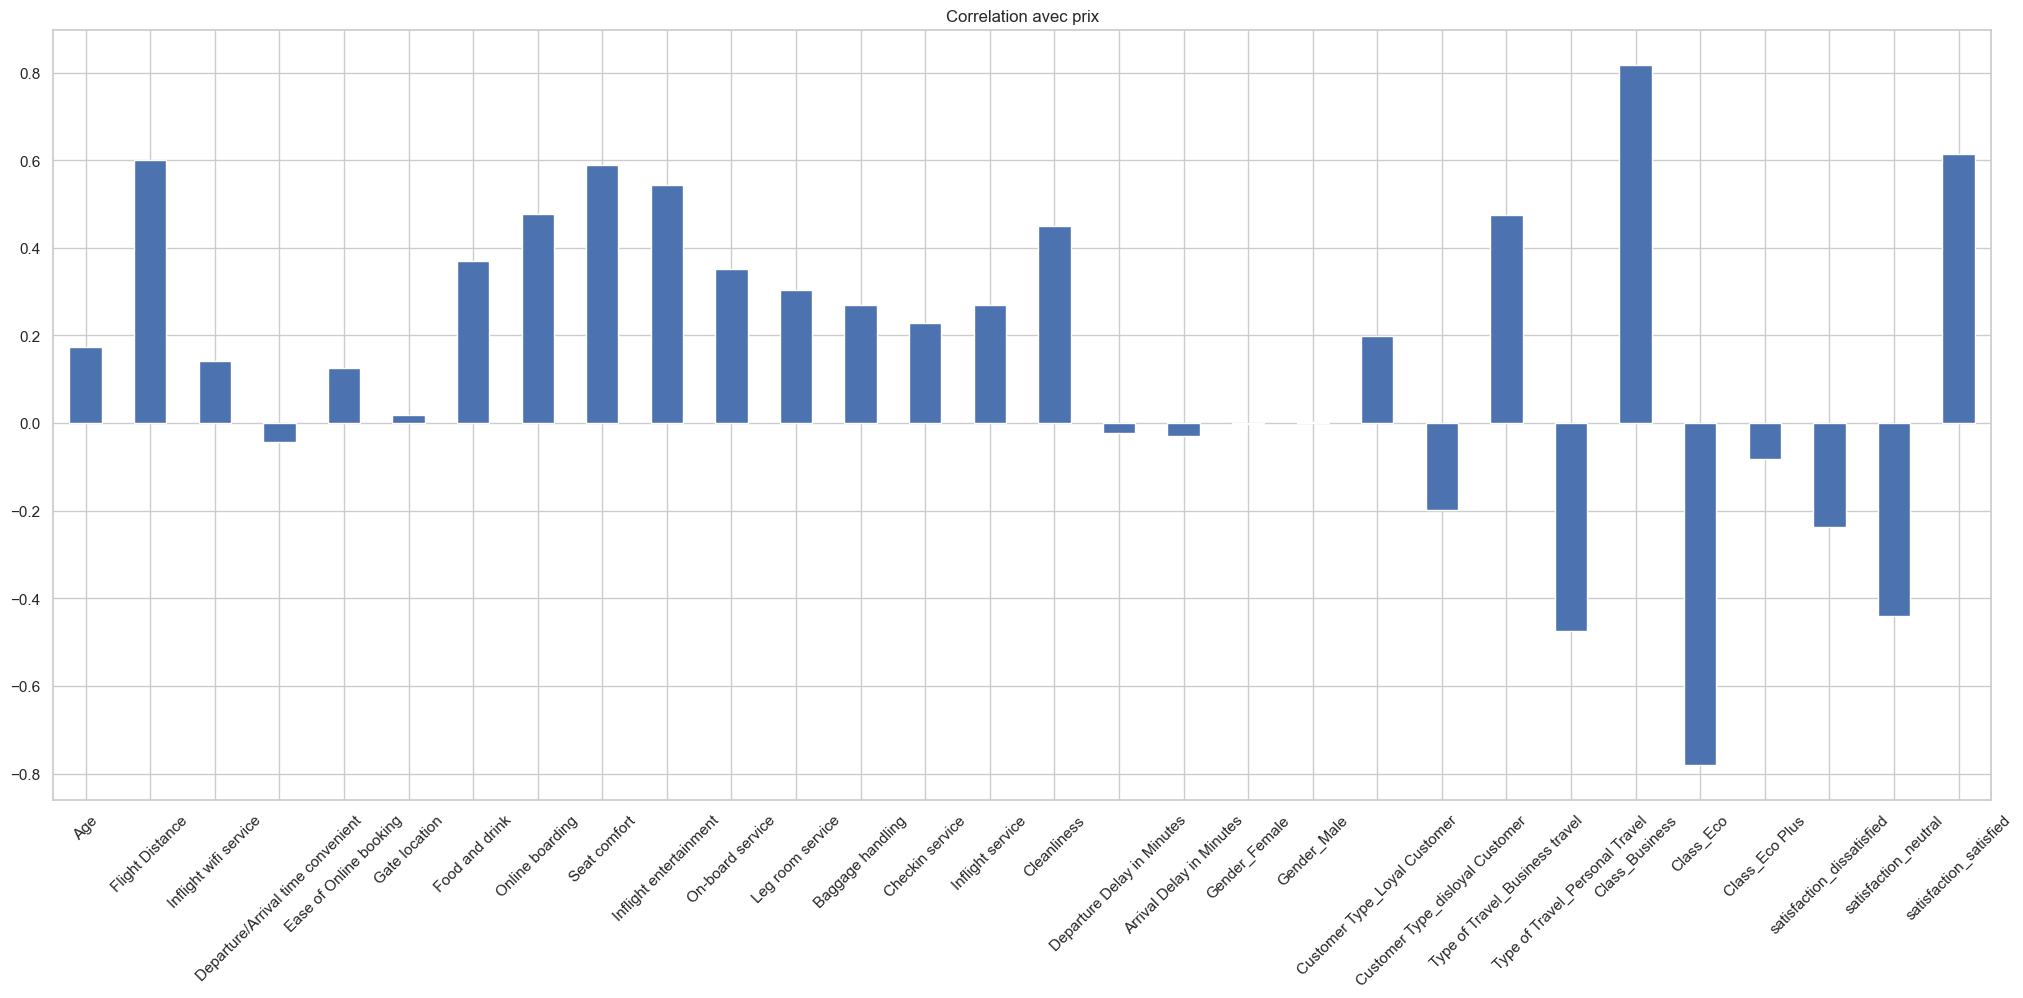

In [32]:
dataset_2 = dataset.drop(columns="Price")
dataset_2.corrwith(dataset["Price"]).plot.bar(
    figsize = (25, 10),
    title = "Correlation avec prix",
    rot = 45,
    grid = True
)

<Axes: >

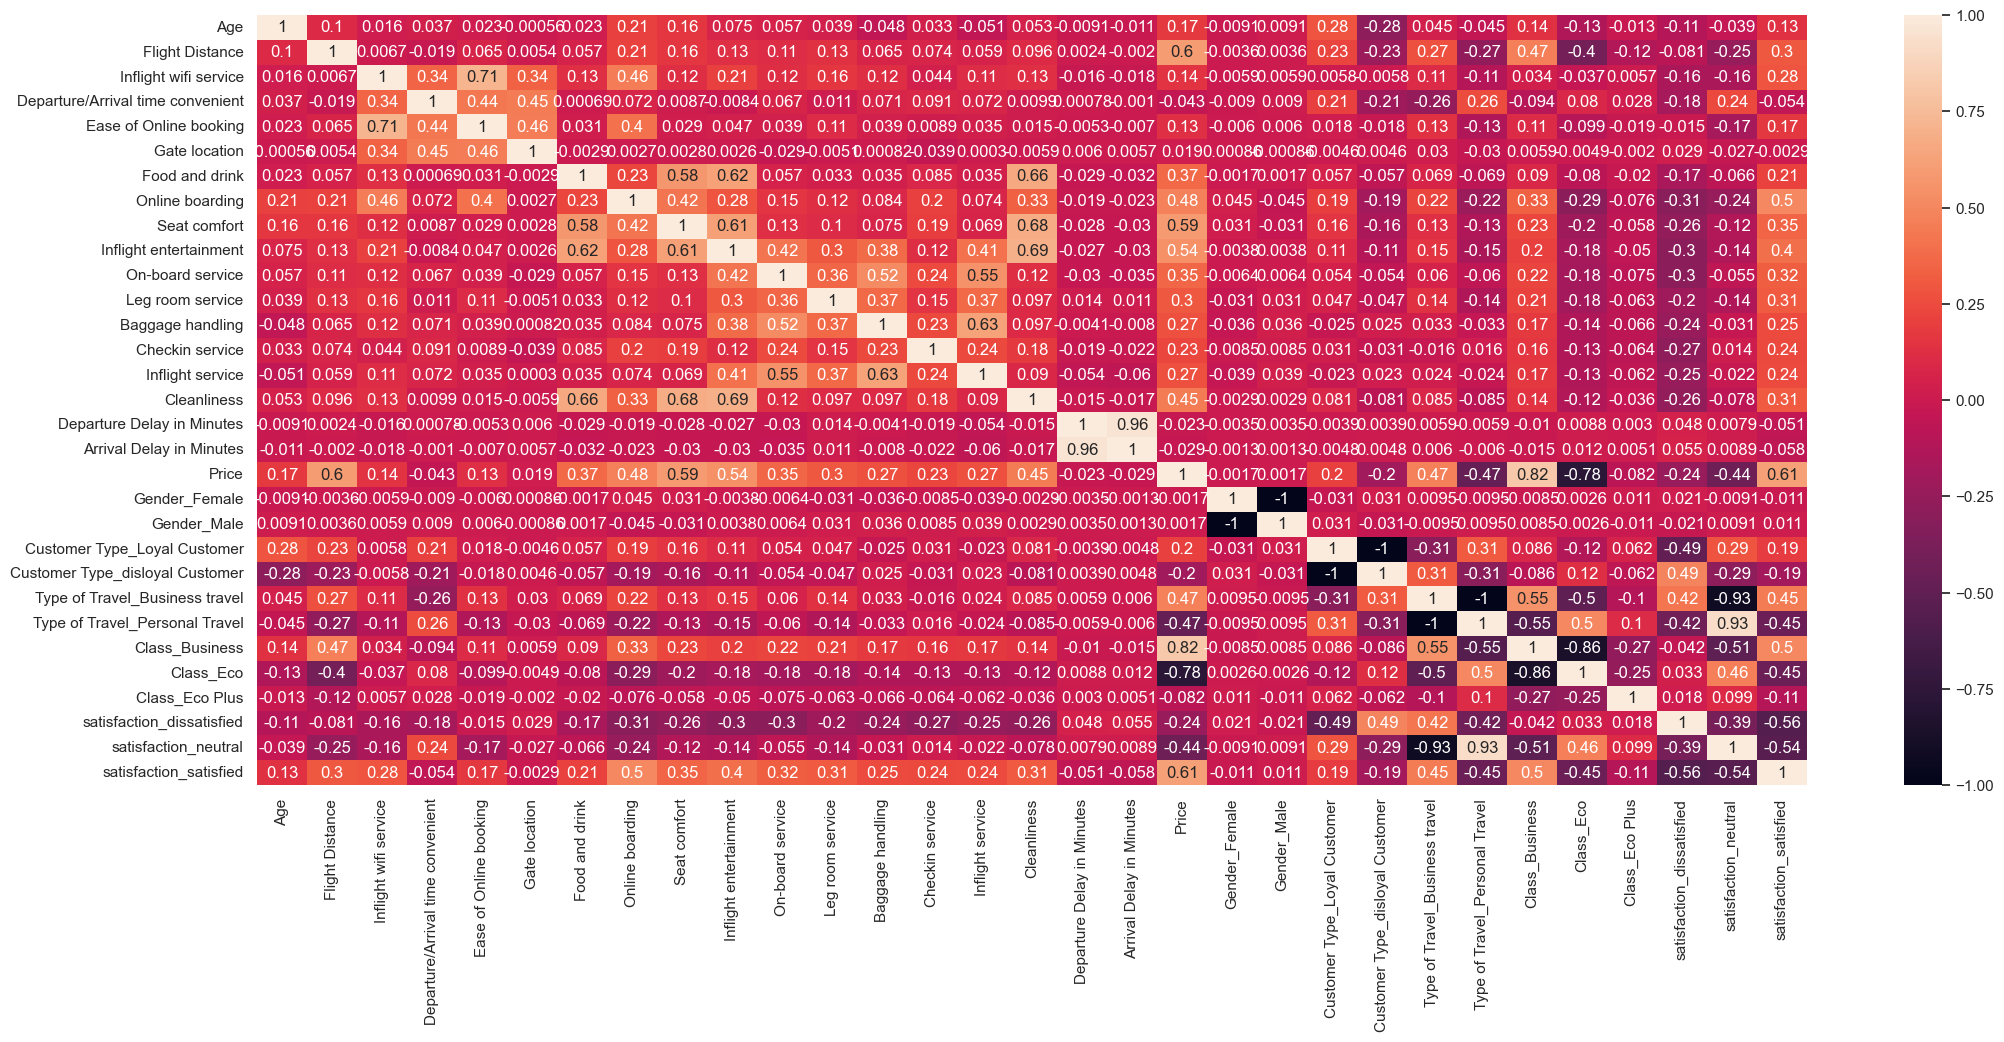

In [33]:
corr = dataset.corr()
plt.figure(figsize = (25, 10))
sns.heatmap(corr, annot = True)

# 6. Train, Test, Split

In [34]:
# variables indépendantes / matrice des features
x = dataset.drop(columns="Price")

# target = variable cible / variable dépendante
y = dataset["Price"]

In [35]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=0)

In [36]:
x_train.shape

(103904, 30)

In [37]:
x_test.shape

(25976, 30)

In [38]:
y_train.shape

(103904,)

In [39]:
y_test.shape

(25976,)

In [40]:
# Feature scaling (mettre toutes les variables à la même échelle)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [41]:
x_train

array([[-1.72874496, -0.96561377,  0.2026231 , ..., -0.63617258,
         1.61645327, -0.87763088],
       [ 1.06838387, -0.08187928,  0.2026231 , ..., -0.63617258,
         1.61645327, -0.87763088],
       [ 0.18508003, -0.28210748, -1.30156372, ...,  1.5719005 ,
        -0.61863836, -0.87763088],
       ...,
       [-2.02317958,  0.6981006 , -1.30156372, ..., -0.63617258,
        -0.61863836,  1.13943119],
       [ 1.14199252,  1.78570381, -0.54947031, ...,  1.5719005 ,
        -0.61863836, -0.87763088],
       [ 1.6572531 , -0.32579364,  0.2026231 , ...,  1.5719005 ,
        -0.61863836, -0.87763088]])

In [42]:
x_test

array([[ 0.62673195, -0.95924287, -1.30156372, ...,  1.5719005 ,
        -0.61863836, -0.87763088],
       [ 0.33229733, -0.70076646, -1.30156372, ..., -0.63617258,
         1.61645327, -0.87763088],
       [ 0.03786272,  1.8758065 , -1.30156372, ...,  1.5719005 ,
        -0.61863836, -0.87763088],
       ...,
       [ 1.06838387,  0.71903355, -0.54947031, ..., -0.63617258,
        -0.61863836,  1.13943119],
       [ 0.92116656,  1.25782944,  0.95471652, ..., -0.63617258,
        -0.61863836,  1.13943119],
       [-0.77183247,  2.66397753,  0.2026231 , ...,  1.5719005 ,
        -0.61863836, -0.87763088]])

In [43]:
# sauvegarder le jeu d'entraînement et le jeu de test
np.savetxt("./x_train.csv", x_train, delimiter=",")
np.savetxt("./X_test.csv", x_test, delimiter=",")

# 7. Création des modèles

## Régression Linéaire

In [44]:
from sklearn.linear_model import LinearRegression

# créer le modèle
model_lr = LinearRegression()

# entraîner le modèle
model_lr.fit(x_train, y_train)

LinearRegression()

In [45]:
# faire des predictions / le jeu de test
y_pred = model_lr.predict(x_test)

In [46]:
from sklearn.metrics import confusion_matrix, mean_squared_error, mean_absolute_error, r2_score

# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
lr_results = pd.DataFrame(
    [["Linear Regression", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

lr_results

,Model,RMSE,MAE,R2
0,Linear Regression,257.451253,204.628475,0.950692


### Validation croisée

In [47]:
from sklearn.model_selection import cross_val_score

accuracies = cross_val_score(estimator=model_lr, X=x_train, y=y_train, cv=10)

print("Accuracy is {:.2f} %".format(accuracies.mean() * 100))
print("Standard Deviation is {:.2f} %".format(accuracies.std() * 100))

Accuracy is 95.03 %
Standard Deviation is 0.04 %


## Régression avec les k plus proches voisins

In [48]:
from sklearn.neighbors import KNeighborsRegressor

# créer le modèle
model_knn = KNeighborsRegressor()

# entraîner le modèle
model_knn.fit(x_train, y_train)

KNeighborsRegressor()

In [49]:
# faire des predictions / le jeu de test
y_pred = model_knn.predict(x_test)

In [50]:
# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
knn_results = pd.DataFrame(
    [["K Neighbors Regressor", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

In [51]:
results = pd.concat([lr_results, knn_results], ignore_index=True)
results

,Model,RMSE,MAE,R2
0,Linear Regression,257.451253,204.628475,0.950692
1,K Neighbors Regressor,187.646257,133.102264,0.973806


### Validation croisée

In [52]:
accuracies = cross_val_score(estimator=model_knn, X=x_train, y=y_train, cv=10)

print("Accuracy is {:.2f} %".format(accuracies.mean() * 100))
print("Standard Deviation is {:.2f} %".format(accuracies.std() * 100))

Accuracy is 97.35 %
Standard Deviation is 0.05 %


## Régression avec un arbre de décision

In [53]:
from sklearn.tree import DecisionTreeRegressor

# créer le modèle
model_dtr = DecisionTreeRegressor()

# entraîner le modèle
model_dtr.fit(x_train, y_train)

DecisionTreeRegressor()

In [54]:
# faire des predictions / le jeu de test
y_pred = model_dtr.predict(x_test)

In [55]:
# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
dtr_results = pd.DataFrame(
    [["Decision Tree Regressor", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

In [56]:
results = pd.concat([results, dtr_results], ignore_index=True)
results

,Model,RMSE,MAE,R2
0,Linear Regression,257.451253,204.628475,0.950692
1,K Neighbors Regressor,187.646257,133.102264,0.973806
2,Decision Tree Regressor,91.340065,65.844818,0.993793


### Validation croisée

In [57]:
accuracies = cross_val_score(estimator=model_dtr, X=x_train, y=y_train, cv=10)

print("Accuracy is {:.2f} %".format(accuracies.mean() * 100))
print("Standard Deviation is {:.2f} %".format(accuracies.std() * 100))

Accuracy is 99.38 %
Standard Deviation is 0.01 %


# 8. Optimisation du meilleur modèle avec GridSearchCV

In [58]:
from sklearn.model_selection import GridSearchCV

# définir la grille d'hyperparamètres
hyperparameters_tree = {
    "criterion": ["squared_error", "friedman_mse", "absolute_error"],
    "max_depth": range(5, 10)
}

# créer le GridSearchCV
search = GridSearchCV(
    estimator=model_dtr,
    param_grid=hyperparameters_tree,
    cv=4,
    scoring="neg_mean_squared_error",
    verbose=10
)

# entrainer le modèle
search.fit(x_train, y_train)

Fitting 4 folds for each of 15 candidates, totalling 60 fits
[CV 1/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 1/4; 1/15] END criterion=squared_error, max_depth=5;, score=-49300.726 total time=   0.1s
[CV 2/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 2/4; 1/15] END criterion=squared_error, max_depth=5;, score=-46904.989 total time=   0.1s
[CV 3/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 3/4; 1/15] END criterion=squared_error, max_depth=5;, score=-48674.284 total time=   0.1s
[CV 4/4; 1/15] START criterion=squared_error, max_depth=5.......................
[CV 4/4; 1/15] END criterion=squared_error, max_depth=5;, score=-47985.821 total time=   0.1s
[CV 1/4; 2/15] START criterion=squared_error, max_depth=6.......................
[CV 1/4; 2/15] END criterion=squared_error, max_depth=6;, score=-32078.363 total time=   0.2s
[CV 2/4; 2/15] START criterion=squared_error, max_depth=6.......

GridSearchCV(cv=4, estimator=DecisionTreeRegressor(),
             param_grid={'criterion': ['squared_error', 'friedman_mse',
                                       'absolute_error'],
                         'max_depth': range(5, 10)},
             scoring='neg_mean_squared_error', verbose=10)

In [59]:
# meilleur modèle
best_model = search.best_estimator_

In [60]:
print("Meilleur score :", search.best_score_)
print("Meilleurs hyperparamètres :", search.best_params_)

Meilleur score : -10563.083854256834
Meilleurs hyperparamètres : {'criterion': 'squared_error', 'max_depth': 9}


# 9. Évaluation finale

In [61]:
# faire des predictions avec le meilleur modèle
y_pred = best_model.predict(x_test)

In [62]:
# calcul des métriques
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# création du tableau des résultats
final_dtr_results = pd.DataFrame(
    [["Final Decision Tree Regressor", rmse, mae, r2]],
    columns=["Model", "RMSE", "MAE", "R2"]
)

final_dtr_results

,Model,RMSE,MAE,R2
0,Final Decision Tree Regressor,102.307924,75.027864,0.992213


In [63]:
results = pd.concat([results, final_dtr_results], ignore_index=True)
results

,Model,RMSE,MAE,R2
0,Linear Regression,257.451253,204.628475,0.950692
1,K Neighbors Regressor,187.646257,133.102264,0.973806
2,Decision Tree Regressor,91.340065,65.844818,0.993793
3,Final Decision Tree Regressor,102.307924,75.027864,0.992213


# 10. Tester sur une nouvelle observation

In [64]:
# créer les caractéristiques du prix du billet
# récupérer le premier enregistrement sous forme de dictionnaire
mon_prix_billet = dataset.iloc[0].to_dict()

mon_prix_billet

{'Age': 19.0,
 'Flight Distance': 353.0,
 'Inflight wifi service': 3,
 'Departure/Arrival time convenient': 4,
 'Ease of Online booking': 3.0,
 'Gate location': 4.0,
 'Food and drink': 2,
 'Online boarding': 3,
 'Seat comfort': 2,
 'Inflight entertainment': 2,
 'On-board service': 5,
 'Leg room service': 5.0,
 'Baggage handling': 5,
 'Checkin service': 2,
 'Inflight service': 2,
 'Cleanliness': 2,
 'Departure Delay in Minutes': 0,
 'Arrival Delay in Minutes': 3.0,
 'Price': 565,
 'Gender_Female': True,
 'Gender_Male': False,
 'Customer Type_Loyal Customer': False,
 'Customer Type_disloyal Customer': True,
 'Type of Travel_Business travel': True,
 'Type of Travel_Personal Travel': False,
 'Class_Business': False,
 'Class_Eco': True,
 'Class_Eco Plus': False,
 'satisfaction_dissatisfied': True,
 'satisfaction_neutral': False,
 'satisfaction_satisfied': False}

In [65]:
# encoder les variables catégorielles
mon_prix_billet_encoded = pd.get_dummies(mon_prix_billet)

# aligner les colonnes sur celles attendues par le scaler
mon_prix_billet_encoded = mon_prix_billet_encoded.reindex(
    columns=sc.feature_names_in_,
    fill_value=0
)

# appliquer le scaler
billet_transforme = sc.transform(mon_prix_billet_encoded)

# faire la prédiction
prediction = best_model.predict(billet_transforme)

print("Prix estimé du billet :", prediction[0])

Prix estimé du billet : 247.90748898678413


In [66]:
# sauvegarder le meilleur modèle
import joblib
joblib.dump(best_model, "model.pkl")

['model.pkl']

# Problème de classification binaire

* Créer une variable binaire à partir de la variable "Satisfaction"
* Nous pouvons créer une nouvelle variable binaire à partir de la variable "Satisfaction" en regroupant les classes "Neutral" et "dissatisfied" en une seule classe. 
* Cette nouvelle variable indiquera si un client est "satisfied" ou "not satisfied".
* Reprendre les étapes de la question 2 avec cette nouvelle variable comme variable cible